Name - Rajat Kumar Majumdar CU240251642

Roll No:49

Section: B

Experiment No. 10

Experiment Name

Character, Digit, or Face Classification using Convolutional Neural Networks (CNNs)

Aim

To design, train, and evaluate a Convolutional Neural Network (CNN) for character, digit, or face classification using a standard image dataset and analyze its performance using appropriate evaluation metrics.

Purpose

Image classification is one of the most important applications of deep learning in computer vision. Convolutional Neural Networks (CNNs) automatically learn hierarchical image features, eliminating the need for handcrafted feature extraction techniques. CNN-based classifiers have become the foundation of modern applications such as handwritten digit
recognition, facial recognition, biometric authentication, medical diagnosis, and intelligent
document processing.

In this experiment, students will develop a CNN-based image classification model using
datasets such as MNIST (handwritten digit recognition), Fashion-MNIST, EMNIST (character
recognition), or CelebA (face recognition). The trained model will be evaluated using standard
performance metrics to assess its classification capability.

Prerequisites

• Basic knowledge of Python programming

• Familiarity with Digital Image Processing and Computer Vision concepts

• Understanding of Artificial Neural Networks (ANNs) and Convolutional Neural
Networks (CNNs)

• Python libraries: TensorFlow/Keras or PyTorch, OpenCV, NumPy, and Matplotlib

• Jupyter Notebook, Google Colab, or Visual Studio Code

Steps

1. Select a standard dataset such as MNIST, Fashion-MNIST, EMNIST, or CelebA for the
classification task.
2. Import the required libraries and load the selected dataset into the development
environment.
3. Perform image preprocessing by resizing (if required), normalization, and splitting the
dataset into training, validation, and testing sets.
4. Design a Convolutional Neural Network (CNN) consisting of convolutional layers,
pooling layers, activation functions, fully connected layers, and an output layer.
5. Configure the model using an appropriate optimizer, loss function, learning rate, batch
size, and number of training epochs.
6. Train the CNN model using the training dataset and monitor the learning process
through training and validation accuracy/loss curves.
7. Evaluate the trained model on the testing dataset using performance metrics such as
Accuracy, Precision, Recall, F1-Score, and Confusion Matrix.
8. Perform predictions on unseen images and compare the predicted labels with the actual
labels.
9. Analyze the model's performance, identify possible misclassifications, and discuss
factors affecting classification accuracy.
10. Summarize the results and discuss the practical applications of CNN-based image
classification in modern computer vision systems.

In [1]:
# Step 1: Import Required Libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


In [2]:
# Step 2: Load the MNIST Dataset

# Load the MNIST handwritten digit dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images shape:", X_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)


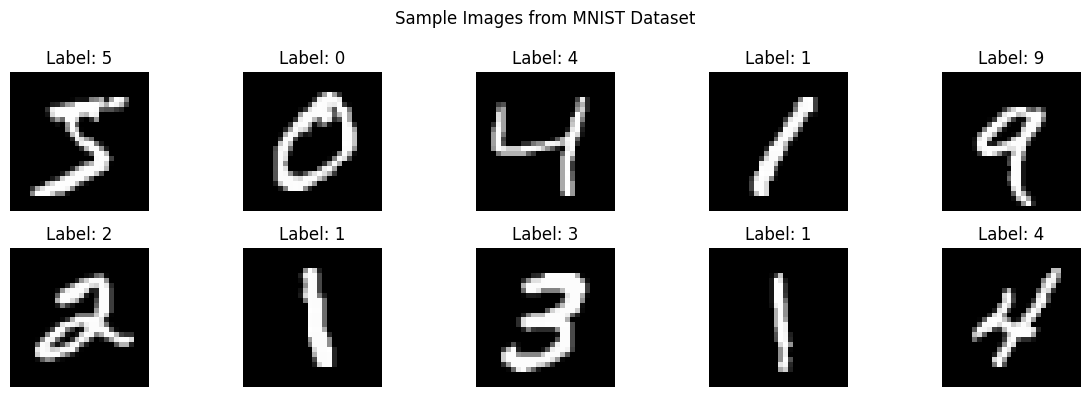

In [4]:
# Step 3: Display Sample Images

# Display the first 10 handwritten digit images
plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("Sample Images from MNIST Dataset")
plt.tight_layout()
plt.show()

In [5]:
# Step 4: Preprocess the Dataset
# Normalize pixel values
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Reshape images for CNN input: height, width, channels
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Convert class labels into one-hot encoded vectors
y_train_cat = to_categorical(y_train, num_classes=10)
y_test_cat = to_categorical(y_test, num_classes=10)

print("Preprocessing completed!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Preprocessing completed!
Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)


In [6]:
# Step 5: Design the CNN Model

# Create the CNN model
model = Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(10, activation="softmax")
])

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Step 6: Compile the CNN Model

# Configure the model
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [9]:
# Step 7: Train the CNN Model

# Train the model
history = model.fit(
    X_train,
    y_train_cat,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

print("Model training completed!")

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 58s 135ms/step - accuracy: 0.8993 - loss: 0.3282 - val_accuracy: 0.9822 - val_loss: 0.0642
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 57s 134ms/step - accuracy: 0.9689 - loss: 0.1027 - val_accuracy: 0.9868 - val_loss: 0.0446
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 68s 102ms/step - accuracy: 0.9775 - loss: 0.0761 - val_accuracy: 0.9893 - val_loss: 0.0387
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - accuracy: 0.9828 - loss: 0.0587 - val_accuracy: 0.9908 - val_loss: 0.0309
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 79s 101ms/step - accuracy: 0.9850 - loss: 0.0491 - val_accuracy: 0.9907 - val_loss: 0.0357
Model training completed!


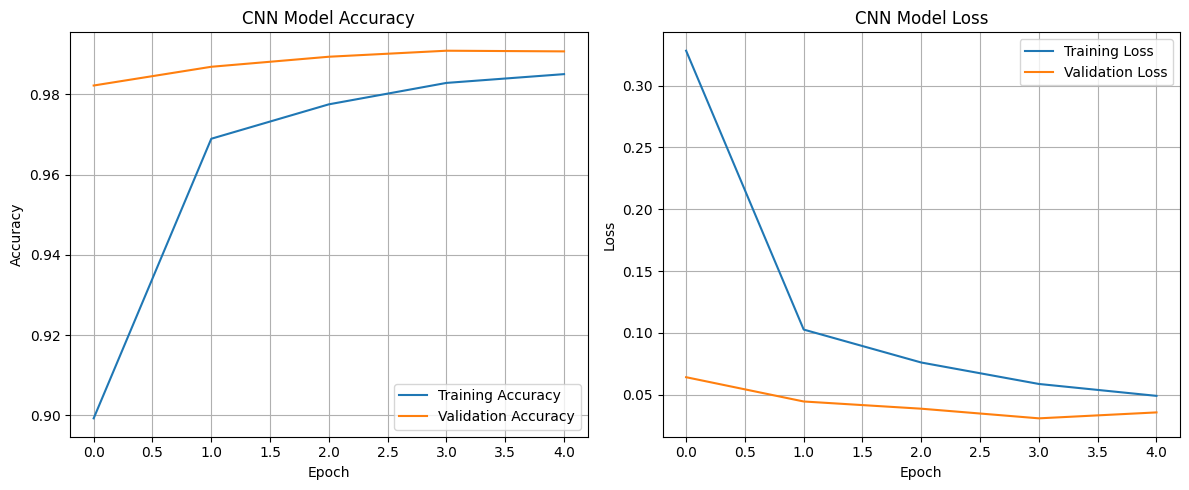

In [10]:
# Step 8: Plot Training and Validation Accuracy and Loss
# Plot accuracy and loss curves
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

CNN MODEL EVALUATION
--------------------
Test Loss  : 0.0270
Accuracy   : 0.9906 (99.06%)
Precision  : 0.9906
Recall     : 0.9906
F1-Score   : 0.9906

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       1.00      0.98      0.99       982
           5       0.99      0.99      0.99       892
           6       1.00      0.99      0.99       958
           7       0.98      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



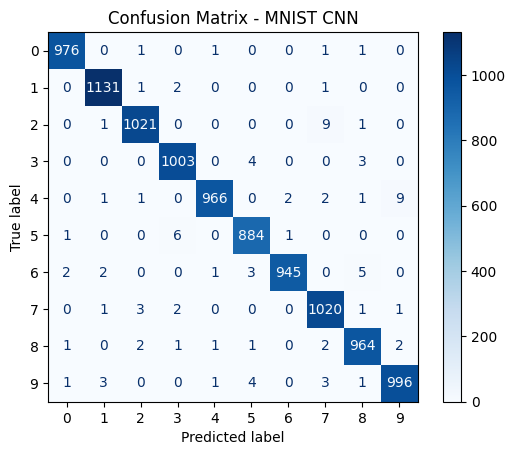

In [11]:
# Step 9: Evaluate the Model Using Performance Metrics

# Evaluate the model on test data
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test_cat,
    verbose=0
)

# Generate predictions
y_pred_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print("CNN MODEL EVALUATION")
print("--------------------")
print(f"Test Loss  : {test_loss:.4f}")
print(f"Accuracy   : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"F1-Score   : {f1:.4f}")

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - MNIST CNN")
plt.show()

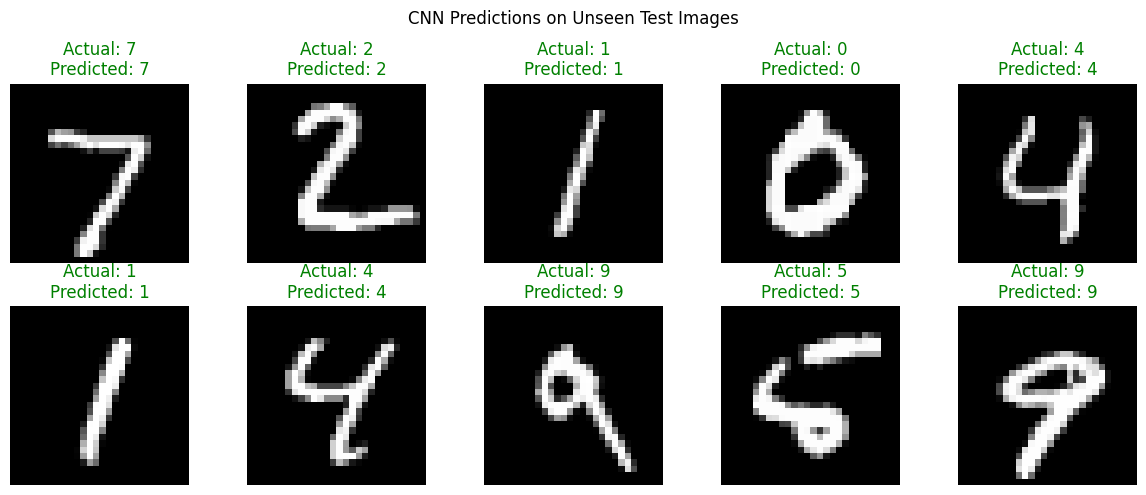

Total test images: 10000
Correct predictions: 9906
Incorrect predictions: 94


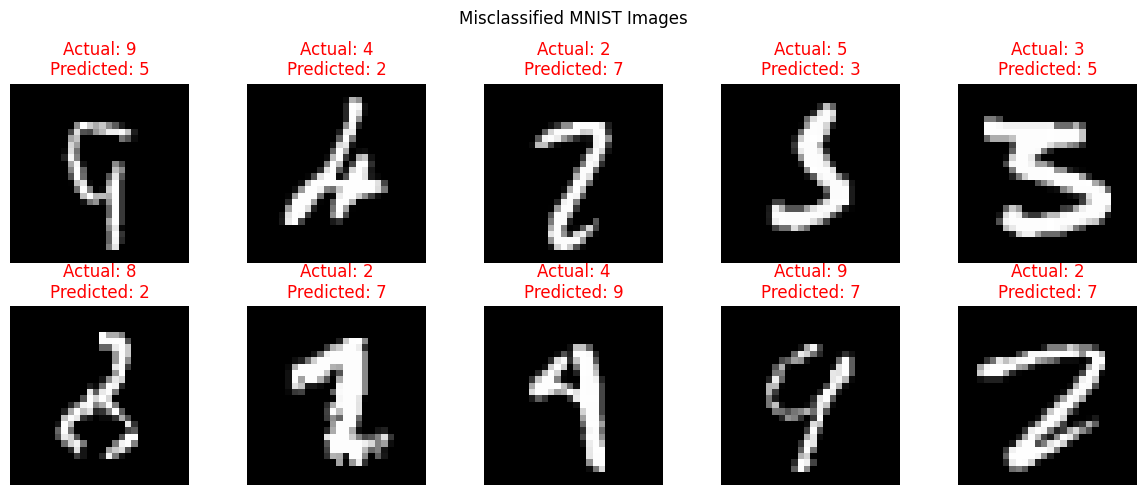

In [12]:
# Step 10: Predict Unseen Images and Analyze Results

# Predict the first 10 test images
predictions = model.predict(X_test[:10], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i].squeeze(), cmap="gray")

    actual = y_test[i]
    predicted = predicted_labels[i]

    color = "green" if actual == predicted else "red"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color
    )
    plt.axis("off")

plt.suptitle("CNN Predictions on Unseen Test Images")
plt.tight_layout()
plt.show()

# Identify incorrectly classified test images
wrong_indices = np.where(y_test != y_pred)[0]

print("Total test images:", len(y_test))
print("Correct predictions:", np.sum(y_test == y_pred))
print("Incorrect predictions:", len(wrong_indices))

# Display up to 10 misclassified images
if len(wrong_indices) > 0:
    plt.figure(figsize=(12, 5))

    for i, idx in enumerate(wrong_indices[:10]):
        plt.subplot(2, 5, i + 1)
        plt.imshow(X_test[idx].squeeze(), cmap="gray")
        plt.title(
            f"Actual: {y_test[idx]}\nPredicted: {y_pred[idx]}",
            color="red"
        )
        plt.axis("off")

    plt.suptitle("Misclassified MNIST Images")
    plt.tight_layout()
    plt.show()
else:
    print("No misclassified images found!")

# Experiment No. 10: CNN-Based Image Classification


### Q1. What is image classification? How does it differ from object detection and image segmentation?

Image classification is a computer vision task in which an image is assigned a label or category based on its contents. For example, a CNN can classify a handwritten image as the digit 0, 1, 2, and so on up to 9.

The differences are as follows:

- Image Classification: Assigns a single class label to an image.
- Object Detection: Identifies objects in an image, classifies them, and locates them using bounding boxes.
- Image Segmentation: Assigns a class label to each pixel of an image to identify the exact regions occupied by objects.

Example: In an image containing a cat and a dog, classification identifies the main class, object detection locates both animals, and segmentation marks the pixels belonging to each animal.

### Q2. Explain the architecture and working principle of a Convolutional Neural Network (CNN).

A Convolutional Neural Network (CNN) is a deep learning model designed primarily for processing images and extracting visual features automatically.

The main layers of a CNN are:

1. Input Layer: Receives the image as a matrix of pixel values.
2. Convolutional Layer: Applies filters to extract features such as edges, curves, and patterns.
3. Activation Function: Introduces non-linearity using functions such as ReLU.
4. Pooling Layer: Reduces the spatial dimensions of feature maps.
5. Flatten Layer: Converts multidimensional feature maps into a one-dimensional vector.
6. Fully Connected Layer: Uses extracted features to perform classification.
7. Output Layer: Produces class probabilities, often using Softmax.

Working principle: The input image passes through convolution and pooling layers to extract important features. These features are then passed to fully connected layers to predict the image class. During training, the network adjusts its weights using backpropagation and an optimization algorithm to minimize the loss function.

### Q3. What is the role of Convolutional Layers, Pooling Layers, and Fully Connected Layers in a CNN?

The roles of these layers are:

- Convolutional Layers: Extract image features using learnable filters. Early layers detect edges and textures, while deeper layers learn more complex patterns.
- Pooling Layers: Reduce the spatial size of feature maps, lower computational requirements, and help the model tolerate small changes in feature locations.
- Fully Connected Layers: Combine extracted features and use them to determine the final class of the image.

For example, in handwritten digit recognition, convolutional layers detect strokes, pooling layers reduce feature-map dimensions, and fully connected layers classify the image as a digit from 0 to 9.

### Q4. Why is image normalization performed before training a deep learning model?

Image normalization is the process of scaling pixel values to a suitable numerical range before training a model.

For example, grayscale images commonly contain pixel values between 0 and 255. These values can be normalized to the range 0 to 1 using:

$$
X_{\text{normalized}}=\frac{X}{255}
$$

Advantages of normalization:

1. Improves numerical stability during training.
2. Helps the optimizer converge more efficiently.
3. Prevents large input values from dominating computations.
4. Makes training more consistent and often improves learning performance.

In the MNIST experiment, normalization converts pixel values from 0–255 to 0–1.

### Q5. Explain the purpose of activation functions such as ReLU and Softmax in CNNs.

Activation functions introduce non-linearity into neural networks, allowing them to learn complex relationships in image data.

1. ReLU (Rectified Linear Unit)

ReLU is commonly used in convolutional and hidden layers.

Its formula is:

$$
f(x)=\max(0,x)
$$

It returns zero for negative inputs and the input itself for positive values. ReLU is computationally efficient and helps neural networks learn complex image features.

2. Softmax

Softmax is generally used in the output layer for multiclass classification. It converts output scores into probabilities whose sum is 1.

$$
P_i=\frac{e^{z_i}}{\sum_j e^{z_j}}
$$

Here, $z_i$ represents the score for class $i$.

In MNIST digit classification, Softmax produces probabilities for the ten classes, representing digits 0–9. The class with the highest probability is selected as the predicted digit.

### Q6. What is a Confusion Matrix? How is it used to evaluate classification performance?

A Confusion Matrix is a table used to compare actual class labels with predicted class labels. It shows how many predictions are correct and how many are incorrect for each class.

For binary classification, it contains four values:

- True Positive (TP): Positive samples correctly classified as positive.
- True Negative (TN): Negative samples correctly classified as negative.
- False Positive (FP): Negative samples incorrectly classified as positive.
- False Negative (FN): Positive samples incorrectly classified as negative.

For multiclass classification, such as MNIST, the confusion matrix contains ten rows and ten columns, corresponding to digits 0–9.

Uses of a Confusion Matrix:

1. Identifies correctly and incorrectly classified samples.
2. Shows which classes are frequently confused.
3. Helps calculate precision, recall, and F1-score.
4. Helps identify weaknesses in a classification model.

For example, if the model frequently confuses digits 4 and 9, the confusion matrix helps identify this problem.

### Q7. Differentiate between Accuracy, Precision, Recall, and F1-Score with suitable examples.

These are standard metrics used to evaluate the performance of a classification model.

| Metric | Definition | Formula |
| --- | --- | --- |
| Accuracy | Proportion of all predictions that are correct | $\frac{TP+TN}{TP+TN+FP+FN}$ |
| Precision | Proportion of predicted positive samples that are truly positive | $\frac{TP}{TP+FP}$ |
| Recall | Proportion of actual positive samples correctly identified | $\frac{TP}{TP+FN}$ |
| F1-Score | Harmonic mean of precision and recall | $\frac{2PR}{P+R}$ |

Example: Suppose a model identifies handwritten digit 8 and produces the following results:

- TP = 40
- TN = 50
- FP = 5
- FN = 5

Then:

- Accuracy = $(40+50)/100 = 90\%$
- Precision = $40/(40+5) = 88.89\%$
- Recall = $40/(40+5) = 88.89\%$
- F1-Score = $88.89\%$

Conclusion: Accuracy measures overall correctness, precision measures the reliability of positive predictions, recall measures how many actual positive cases are found, and F1-score balances precision and recall.

### Q8. Compare traditional feature-based image classification methods (e.g., SIFT/HOG + SVM) with CNN-based classification.

Traditional image classification methods rely on manually designed feature extraction techniques, whereas CNNs learn features automatically from training data.

| Feature | Traditional Methods | CNN-Based Methods |
| --- | --- | --- |
| Feature extraction | Handcrafted features such as HOG and SIFT | Automatically learned features |
| Classifier | Commonly SVM or another traditional classifier | Neural network classification layers |
| Data requirements | Can work well with smaller datasets | Often benefits from larger datasets |
| Computational cost | Feature extraction and training may be relatively inexpensive | Training can require substantial computation |
| Feature learning | Limited by manually designed features | Learns hierarchical image representations |
| Accuracy | Effective for certain simpler tasks | Often superior on complex image tasks |
| Adaptability | May require feature redesign | Can learn new features through training or fine-tuning |

Conclusion: Traditional methods can be effective for smaller or simpler problems, while CNNs are generally preferred for complex image classification because they learn relevant features directly from images.

### Q9. Mention five real-world applications of CNN-based image classification.

Five important applications of CNN-based image classification are:

1. Facial Recognition: Identifying or verifying individuals using facial images.
2. Medical Image Analysis: Classifying X-rays, MRI scans, and other medical images to support disease detection.
3. Handwritten Character Recognition: Recognizing digits, letters, and handwritten documents.
4. Agriculture: Identifying plant diseases and classifying crops from leaf images.
5. Autonomous Vehicles: Classifying traffic signs, road scenes, and objects to support driving systems.

CNNs are also used in industrial quality inspection, wildlife monitoring, satellite image analysis, and biometric authentication.

### Q10. How can Data Augmentation, Transfer Learning, and Hyperparameter Tuning improve the performance of deep learning-based image classification models?

These techniques improve a model's accuracy, generalization, and training efficiency.

1. Data Augmentation

Data augmentation artificially creates variations of training images using transformations such as rotation, flipping, cropping, shifting, and zooming.

Benefits:

- Increases training-data diversity.
- Reduces overfitting.
- Improves generalization to unseen images.

For handwritten digits, small shifts and rotations can help the CNN recognize digits written in different styles. Transformations must preserve the correct label.

2. Transfer Learning

Transfer learning uses a model previously trained on a large dataset as the starting point for a new classification task.

For example, a pretrained MobileNet or ResNet model can be adapted to classify plant diseases or facial images.

Benefits:

- Reduces training time.
- Requires less labeled data in many cases.
- Reuses useful features learned from previous tasks.

3. Hyperparameter Tuning

Hyperparameter tuning involves selecting suitable training settings, such as:

- Learning rate
- Batch size
- Number of epochs
- Number of convolutional layers
- Number of filters
- Dropout rate
- Optimizer

Benefits:

- Improves model performance.
- Helps prevent overfitting and underfitting.
- Can improve convergence speed and generalization.

Conclusion: Data augmentation improves data diversity, transfer learning reuses learned features, and hyperparameter tuning identifies effective model settings. Together, these techniques can improve CNN-based image classification performance.

## Result

A Convolutional Neural Network (CNN) was designed, trained, and evaluated using the MNIST handwritten digit dataset. The model learned image features and classified handwritten digits into ten classes (0–9). Its performance was assessed using accuracy, precision, recall, F1-score, training and validation curves, and a confusion matrix.

The experiment demonstrates that CNNs are effective for image classification and have practical applications in computer vision, character recognition, facial recognition, and medical image analysis.